<a href="https://colab.research.google.com/github/AnshuAnshu01/Data_Analytics_Python/blob/main/Patient_Records%20/%20Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv("patient_records.csv")

age_group
31-45    31540
46-60    23128
18-30    20636
61-75    12051
76+       7809
0-17      4836
Name: count, dtype: int64


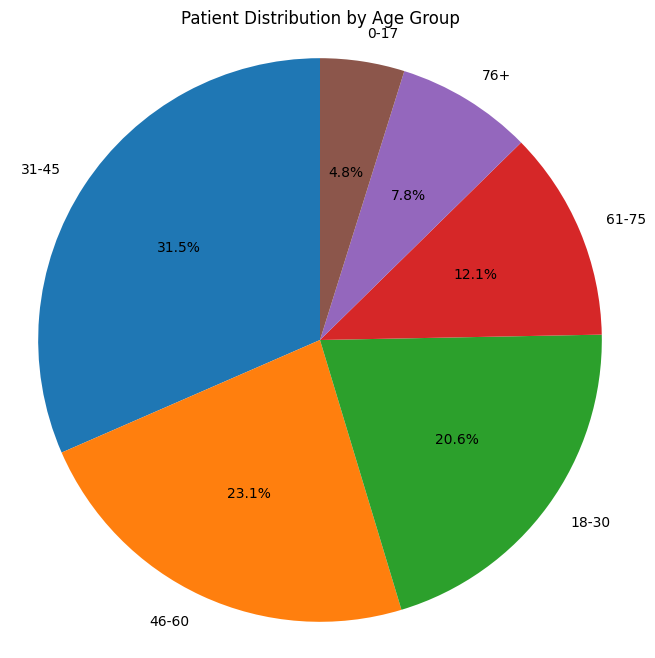

In [ ]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 17, 30, 45, 60, 75, 100],
    labels=["0-17", "18-30", "31-45", "46-60", "61-75", "76+"]
)
age_counts = df["age_group"].value_counts()
print(age_counts)

plt.figure(figsize=(8, 8))

plt.pie(age_counts,labels=age_counts.index,autopct="%1.1f%%",startangle=90)

plt.title("Patient Distribution by Age Group")
plt.axis("equal")
plt.show()

In [ ]:
print(df["state"].value_counts().head(1))
print(df["city"].value_counts().head(1))

state
Maharashtra    17846
Name: count, dtype: int64
city
Delhi    9959
Name: count, dtype: int64


In [ ]:
print(df["admission_type"].value_counts())

admission_type
Emergency     34615
Outpatient    28070
Elective      20401
Urgent        16914
Name: count, dtype: int64


In [ ]:
print(df["primary_diagnosis"].value_counts().head(10))

primary_diagnosis
Essential Hypertension      9213
Type 2 Diabetes Mellitus    8088
Viral Fever / Influenza     6855
Pneumonia                   4270
Iron Deficiency Anemia      3898
Coronary Artery Disease     3833
Asthma                      3561
Acute Gastroenteritis       3531
Dengue Fever                3514
Urinary Tract Infection     3383
Name: count, dtype: int64


In [ ]:
df["admission_month"] = pd.to_datetime(
    df["admission_date"]
).dt.month_name()

print(df["admission_month"].value_counts())

admission_month
March        8638
May          8574
July         8563
December     8516
January      8470
October      8434
August       8326
November     8294
September    8178
April        8135
June         8131
February     7741
Name: count, dtype: int64


In [ ]:
print(df.groupby("age_group")["bmi"].mean())

age_group
0-17     17.238379
18-30    24.865187
31-45    24.918795
46-60    24.934793
61-75    24.999627
76+      25.012998
Name: bmi, dtype: float64


/tmp/ipykernel_471/1685012995.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby("age_group")["bmi"].mean())


In [ ]:
missing = df.isnull().sum()

print(missing[missing > 0].sort_values(ascending=False))

hba1c_pct                 12145
total_cholesterol_mgdl     8098
creatinine_mgdl            3914
hemoglobin_gdl             3000
blood_glucose_mgdl         2887
dtype: int64


In [ ]:
r = df.groupby("icu_admission")["length_of_stay_days"].mean()

print(r)


icu_admission
0    2.196534
1    5.409374
Name: length_of_stay_days, dtype: float64


In [ ]:
result = df.groupby("admission_type")[
    "length_of_stay_days"
].mean().sort_values(ascending=False)

print(result)

admission_type
Emergency     3.545515
Elective      2.931670
Urgent        2.895530
Outpatient    0.000000
Name: length_of_stay_days, dtype: float64


department
Critical Care       127505.883391
Oncology             95451.190167
Obstetrics           90492.333253
General Surgery      90409.751881
Nephrology           87829.488390
Neurology            81416.591222
Pulmonology          61979.413748
Cardiology           53974.315146
Orthopedics          41233.197329
General Medicine     40382.915826
Gastroenterology     21512.935527
Endocrinology        21484.944800
Psychiatry           21359.511757
Urology              21249.846813
Hematology           21108.719356
Dermatology          20889.593130
Pediatrics           20679.159762
Name: total_bill_inr, dtype: float64


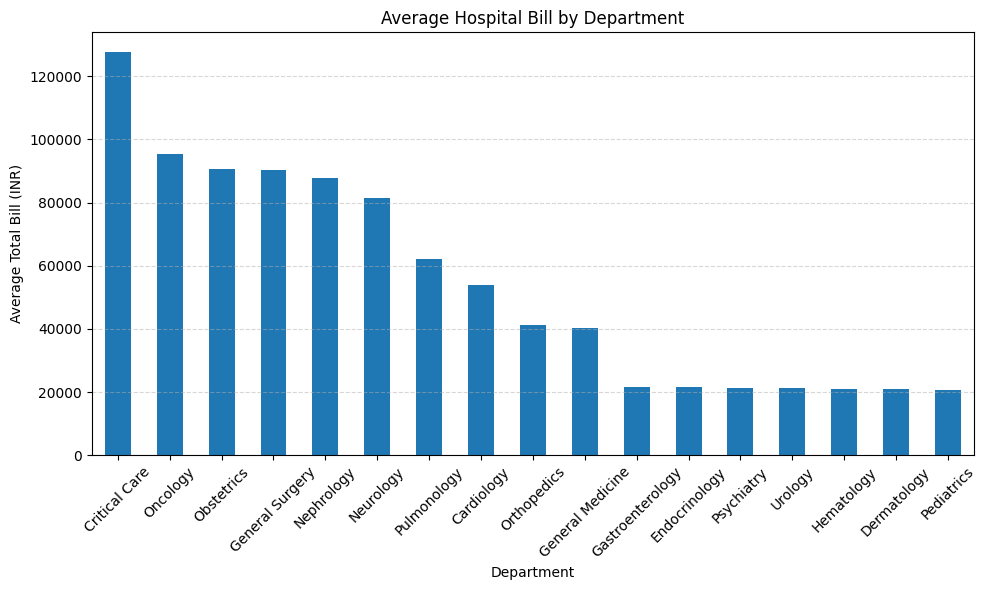

In [ ]:
result = df.groupby("department")[
    "total_bill_inr"
].mean().sort_values(ascending=False)

print(result)

plt.figure(figsize=(10, 6))

result.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Hospital Bill by Department")
plt.xlabel("Department")
plt.ylabel("Average Total Bill (INR)")

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Insurance %: 59.57605302677379
Patient %: 30.140734621099774
Difference %: 10.283212352126434


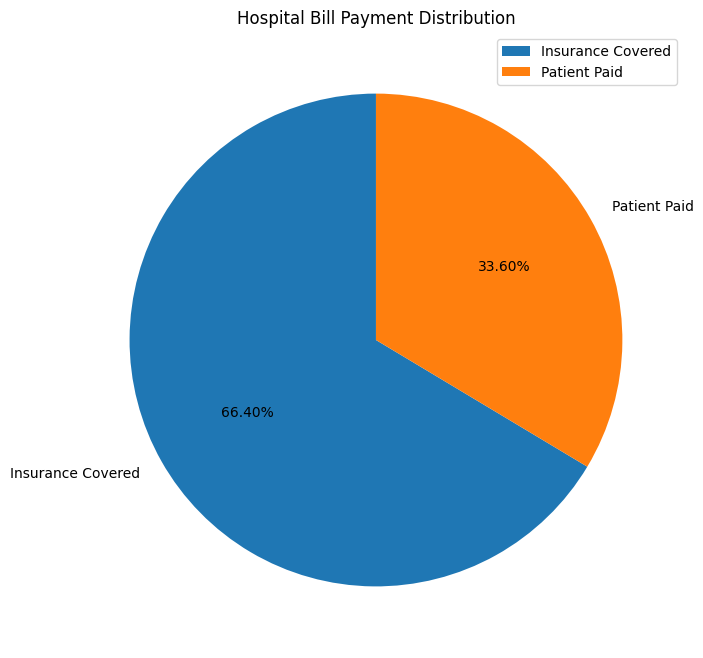

In [ ]:
total_bill = df["total_bill_inr"].sum()

insurance = df["insurance_covered_inr"].sum()
patient = df["patient_paid_inr"].sum()

print("Insurance %:", insurance / total_bill * 100)
print("Patient %:", patient / total_bill * 100)

print(
    "Difference %:",
    (total_bill - insurance - patient) / total_bill * 100
)

labels = ["Insurance Covered", "Patient Paid"]
values = [insurance, patient]

plt.figure(figsize=(8, 8))

plt.pie(
    values,
    labels=labels,
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Hospital Bill Payment Distribution")
plt.legend()
plt.show()

insurance_provider
Self-Pay                    34611.022667
ICICI Lombard               13587.895886
HDFC ERGO                   12725.375880
Niva Bupa                   12710.831034
Care Health                 12621.511741
Star Health                 12506.291474
Ayushman Bharat (PM-JAY)     4518.047215
CGHS                         3497.037414
ESIC                         3456.425149
Name: patient_paid_inr, dtype: float64


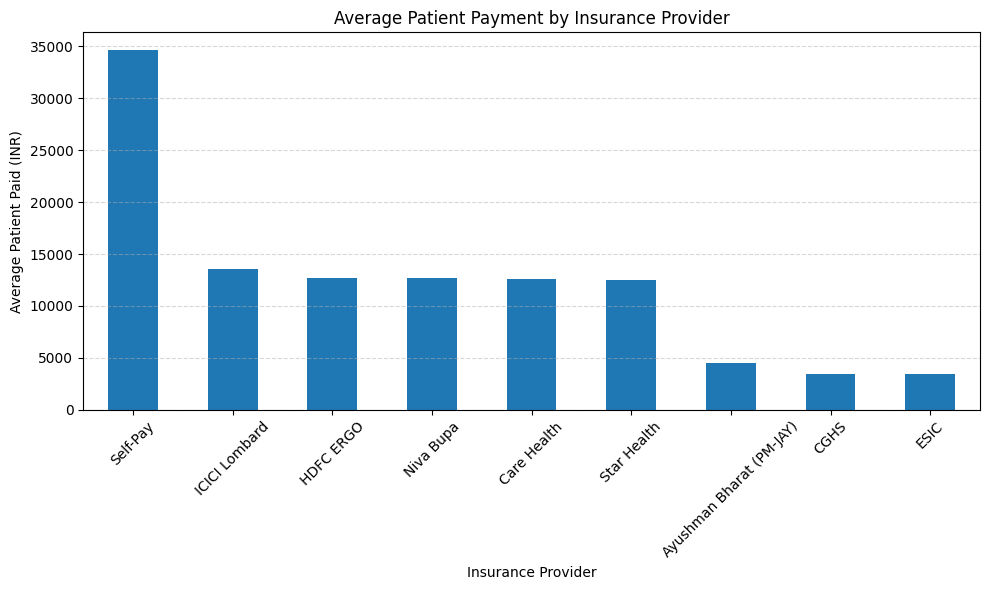

In [ ]:
result = df.groupby("insurance_provider")[
    "patient_paid_inr"
].mean().sort_values(ascending=False)

print(result)


plt.figure(figsize=(10, 6))

result.plot(kind="bar")

plt.title("Average Patient Payment by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Average Patient Paid (INR)")

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
correlation = df[
    ["length_of_stay_days", "total_bill_inr"]
].corr()

print(correlation)

                     length_of_stay_days  total_bill_inr
length_of_stay_days             1.000000        0.587531
total_bill_inr                  0.587531        1.000000


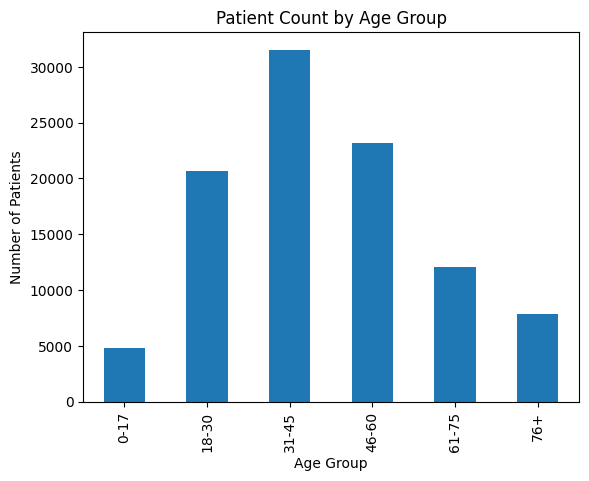

In [ ]:
df["age_group"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Patient Count by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Patients")
plt.show()

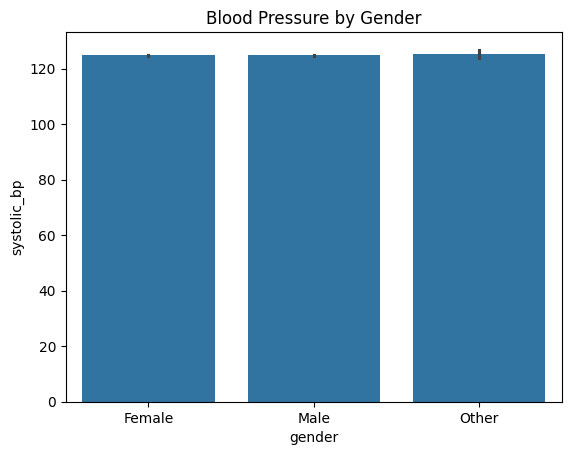

In [ ]:


sns.barplot(
    data=df,
    x="gender",
    y="systolic_bp"
)

plt.title("Blood Pressure by Gender")
plt.show()

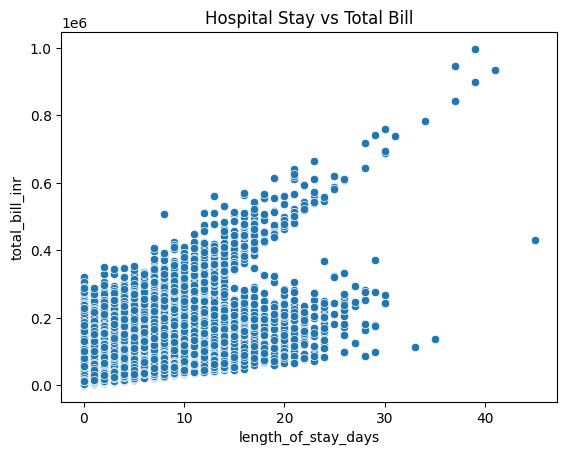

In [ ]:
sns.scatterplot(
    data=df,
    x="length_of_stay_days",
    y="total_bill_inr"
)

plt.title("Hospital Stay vs Total Bill")
plt.show()

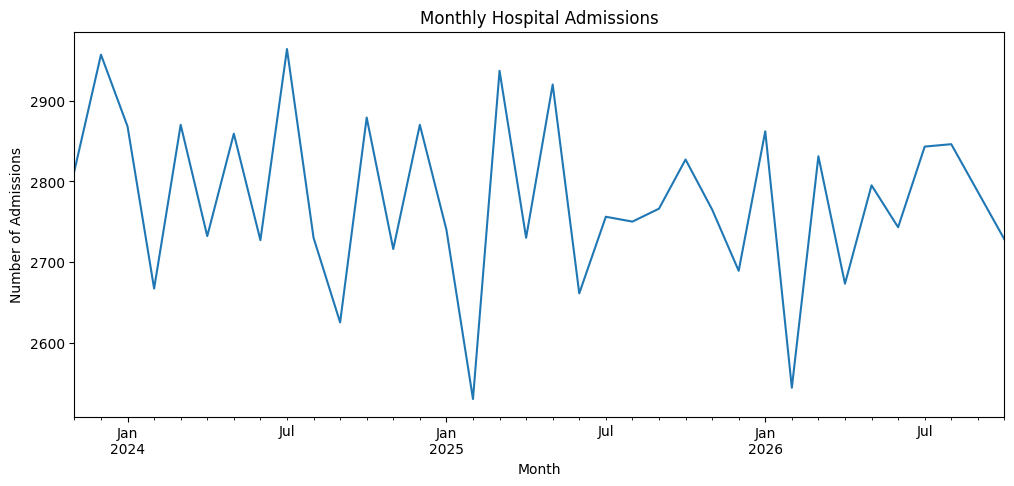

In [ ]:
df["admission_date"] = pd.to_datetime(
    df["admission_date"]
)

monthly = df.groupby(
    df["admission_date"].dt.to_period("M")
).size()

monthly.plot(kind="line", figsize=(12, 5))

plt.title("Monthly Hospital Admissions")
plt.xlabel("Month")
plt.ylabel("Number of Admissions")
plt.show()